In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import random
import shutil

from pathlib import Path
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

In [2]:
dataset_path = Path(
    "../dataset/raw"
)

print("Dataset Exists:", dataset_path.exists())
print("Total Classes:", len(list(dataset_path.iterdir())))
print("Classes:", [p.name for p in dataset_path.iterdir() if p.is_dir()])

Dataset Exists: True
Total Classes: 10
Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_healthy', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_mosaic_virus', 'Tomato__Tomato_YellowLeaf__Curl_Virus']


In [3]:
print(tf.config.list_physical_devices("GPU"))

[]


In [23]:
random.seed(36)

selected_images = []

image_extensions = [".jpg", ".jpeg", ".png"]

for class_folder in dataset_path.iterdir():

    if class_folder.is_dir():

        images = [
            p for p in class_folder.iterdir()
            if p.is_file() and p.suffix.lower() in image_extensions
        ]

        sample_count = max(1, int(len(images) * 0.30))

        selected = random.sample(
            images,
            sample_count
        )

        selected_images.extend(selected)

print("Total selected images:", len(selected_images))

Total selected images: 4799


In [25]:
small_dataset_path = Path("/content/tomato_30_percent")

if small_dataset_path.exists():
    shutil.rmtree(small_dataset_path)

small_dataset_path.mkdir(parents=True, exist_ok=True)

for image_path in selected_images:

    class_name = image_path.parent.name

    target_folder = small_dataset_path / class_name
    target_folder.mkdir(parents=True, exist_ok=True)

    shutil.copy2(
        image_path,
        target_folder / image_path.name
    )

print("30% dataset created successfully!")

30% dataset created successfully!


In [26]:
for class_folder in sorted(small_dataset_path.iterdir()):

    if class_folder.is_dir():

        count = len(list(class_folder.iterdir()))

        print(class_folder.name, ":", count)

Tomato__Target_Spot : 421
Tomato__Tomato_mosaic_virus : 111
Tomato__Tomato_YellowLeaf__Curl_Virus : 962
Tomato_Bacterial_spot : 638
Tomato_Early_blight : 300
Tomato_healthy : 477
Tomato_Late_blight : 572
Tomato_Leaf_Mold : 285
Tomato_Septoria_leaf_spot : 531
Tomato_Spider_mites_Two_spotted_spider_mite : 502


In [27]:
train_dataset = tf.keras.utils.image_dataset_from_directory(
    small_dataset_path,
    validation_split=0.30,
    subset="training",
    seed=42,
    image_size=(128, 128),
    batch_size=32,
    label_mode="int"
)


temp_dataset = tf.keras.utils.image_dataset_from_directory(
    small_dataset_path,
    validation_split=0.30,
    subset="validation",
    seed=42,
    image_size=(128, 128),
    batch_size=32,
    label_mode="int"
)




Found 4799 files belonging to 10 classes.
Using 3360 files for training.
Found 4799 files belonging to 10 classes.
Using 1439 files for validation.


In [28]:
class_names = train_dataset.class_names

num_classes = len(class_names)

val_batches = tf.data.experimental.cardinality(temp_dataset)

validation_dataset = temp_dataset.take(val_batches // 2)

test_dataset = temp_dataset.skip(val_batches // 2)

print("Classes:", class_names)
print("Number of classes:", num_classes)

Classes: ['Tomato_Bacterial_spot', 'Tomato_Early_blight', 'Tomato_Late_blight', 'Tomato_Leaf_Mold', 'Tomato_Septoria_leaf_spot', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato__Target_Spot', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato__Tomato_mosaic_virus', 'Tomato_healthy']
Number of classes: 10


In [29]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.shuffle(500).prefetch(AUTOTUNE)

validation_dataset = validation_dataset.prefetch(AUTOTUNE)

test_dataset = test_dataset.prefetch(AUTOTUNE)

In [19]:
print("Train batches:",
      tf.data.experimental.cardinality(train_dataset).numpy())

print("Validation batches:",
      tf.data.experimental.cardinality(validation_dataset).numpy())

print("Test batches:",
      tf.data.experimental.cardinality(test_dataset).numpy())

Train batches: 105
Validation batches: 22
Test batches: 23


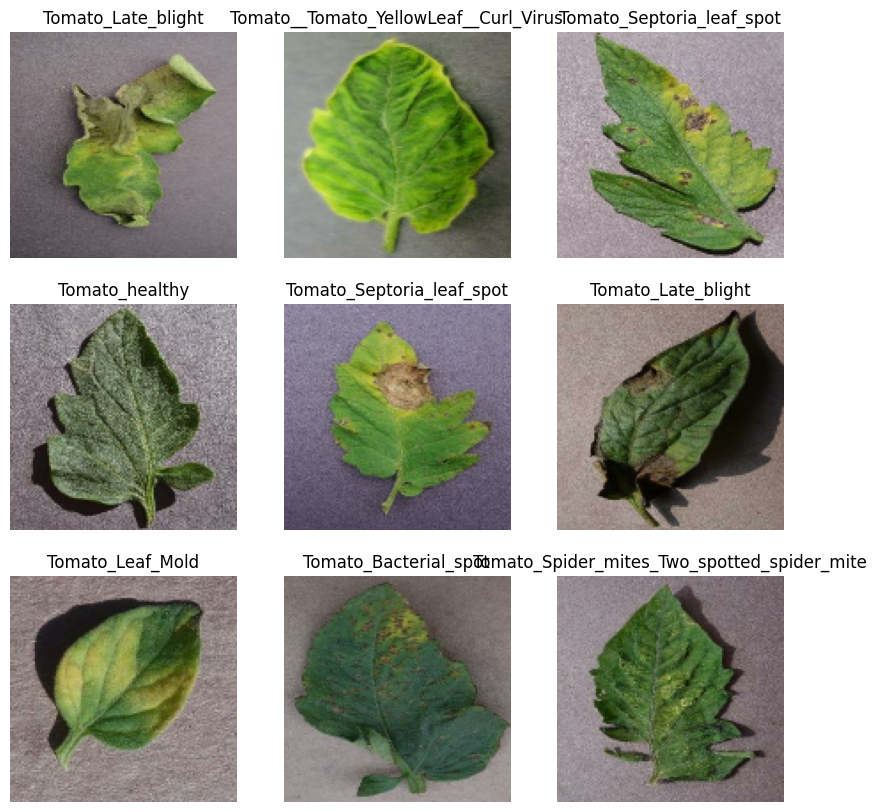

In [30]:
plt.figure(figsize=(10, 10))

for images, labels in train_dataset.take(1):

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

plt.show()

In [31]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [32]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(128, 128, 3)),

    data_augmentation,

    tf.keras.layers.Rescaling(1./255),

    # First Convolution Block
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolution Block
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Third Convolution Block
    tf.keras.layers.Conv2D(128, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Feature Extraction Output
    tf.keras.layers.GlobalAveragePooling2D(),

    # Classification Layers
    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(
        num_classes,
        activation="softmax"
    )
])

In [33]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_2 (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,050 (433.79 KB)

 Trainable params: 111,050 (433.79 KB)

 Non-trainable params: 0 (0.00 B)

In [34]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]
)

In [35]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.2,
    patience=2,
    min_lr=0.00001
)

In [36]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=15,
    callbacks=[early_stop, reduce_lr]
)

Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 196ms/step - accuracy: 0.2330 - loss: 2.0822 - val_accuracy: 0.2670 - val_loss: 1.8942 - learning_rate: 0.0010
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 219ms/step - accuracy: 0.3357 - loss: 1.8354 - val_accuracy: 0.4432 - val_loss: 1.6619 - learning_rate: 0.0010
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 216ms/step - accuracy: 0.4241 - loss: 1.6404 - val_accuracy: 0.4901 - val_loss: 1.4345 - learning_rate: 0.0010
Epoch 4/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 214ms/step - accuracy: 0.4961 - loss: 1.4134 - val_accuracy: 0.5199 - val_loss: 1.3133 - learning_rate: 0.0010
Epoch 5/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 24s 214ms/step - accuracy: 0.5494 - loss: 1.2843 - val_accuracy: 0.6009 - val_loss: 1.0991 - learning_rate: 0.0010
Epoch 6/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 209ms/step - accuracy: 0.5842 - loss: 1.1647 - val_accuracy: 0.5923 - val_loss: 1.0418 - learning_rate: 0.0010
Epoch 7/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 27s 248ms/step - accuracy: 0.6

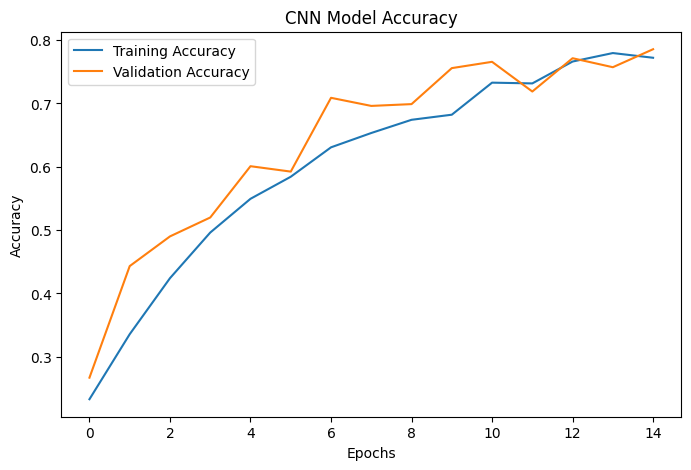

In [37]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("CNN Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()
plt.show()

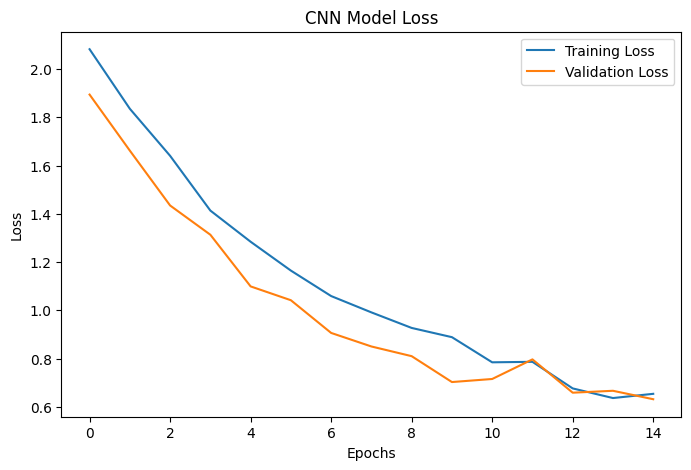

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("CNN Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.show()

In [39]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy Percentage:", test_accuracy * 100)

23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.7932 - loss: 0.5728
Test Loss: 0.5728443264961243
Test Accuracy: 0.7931972742080688
Test Accuracy Percentage: 79.31972742080688


In [40]:
y_true = []
y_pred = []

for images, labels in test_dataset:

    predictions = model.predict(images, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

In [41]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=range(num_classes),
        target_names=class_names,
        zero_division=0
    )
)

                                             precision    recall  f1-score   support

                      Tomato_Bacterial_spot       0.88      0.84      0.86        82
                        Tomato_Early_blight       0.69      0.61      0.65        41
                         Tomato_Late_blight       0.69      0.73      0.71        85
                           Tomato_Leaf_Mold       0.85      0.57      0.68        49
                  Tomato_Septoria_leaf_spot       0.77      0.83      0.80        77
Tomato_Spider_mites_Two_spotted_spider_mite       0.83      0.53      0.65        81
                        Tomato__Target_Spot       0.66      0.76      0.71        83
      Tomato__Tomato_YellowLeaf__Curl_Virus       0.88      0.97      0.92       153
                Tomato__Tomato_mosaic_virus       0.85      1.00      0.92        17
                             Tomato_healthy       0.84      0.99      0.90        67

                                   accuracy                    

<Figure size 1200x1000 with 0 Axes>

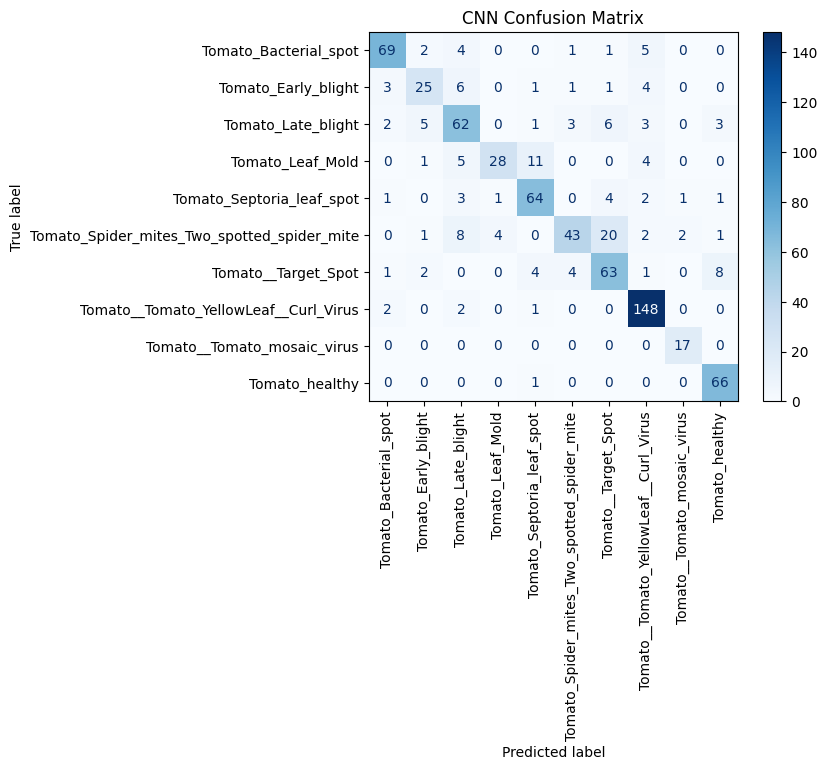

In [42]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=range(num_classes)
)

plt.figure(figsize=(12, 10))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    cmap="Blues",
    xticks_rotation=90,
    values_format="d"
)

plt.title("CNN Confusion Matrix")
plt.show()

In [43]:
model_path = Path(
    "../models"
)

model_path.mkdir(parents=True, exist_ok=True)

model.save(
    model_path / "tomato_disease_cnn.keras"
)

print("CNN Model Saved Successfully!")

CNN Model Saved Successfully!
